# Industrial production forecasting: ARIMA and bootstrap uncertainty

**Research question:** How effectively can a parsimonious ARIMA model capture temporal dependence in U.S. industrial production, and how sensitive are its 50-month prediction intervals to the innovation distribution?

This notebook reproduces the submitted report from a frozen FRED INDPRO snapshot. The estimation window is **October 2006–September 2026 (240 months)**, approved for the original project. All COVID observations remain unchanged. The original index scale is retained; logs are not shown as inferior or ruled out by a formal test. We use only the original candidate orders and selected no-drift ARIMA(2,1,0), not a new automated search.

Run from the repository root with `python scripts/reproduce.py`, or open this notebook in an environment containing `requirements.txt`. All paths are repository-relative. The notebook creates the report figures, result tables and validation record; it does not download data or change the report. See [the final PDF](../report/Project_1.pdf).

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from IPython.display import display, Markdown
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

ROOT = Path.cwd()
if not (ROOT / 'data/reference_results.json').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'data/reference_results.json').is_file():
    raise FileNotFoundError('Run from the repository root or notebooks/ directory.')
FIGURES, RESULTS = ROOT / 'figures', ROOT / 'results'
FIGURES.mkdir(exist_ok=True); RESULTS.mkdir(exist_ok=True)
reference = json.loads((ROOT / 'data/reference_results.json').read_text())
raw_path = ROOT / 'data/raw/INDPRO_2026-10-22.csv'
raw_hash = hashlib.sha256(raw_path.read_bytes()).hexdigest()
assert raw_hash == reference['source_sha256']
assert hashlib.sha256((ROOT / 'report/Project_1.pdf').read_bytes()).hexdigest() == reference['report_sha256']
original = pd.read_csv(raw_path, parse_dates=['observation_date'], index_col='observation_date')['INDPRO']
y = original.loc['2006-10-01':'2026-09-01'].copy().asfreq('MS')
assert y.index.equals(pd.date_range('2006-10-01','2026-09-01',freq='MS'))
assert len(y) == 240 and y.notna().all()
assert np.array_equal(y.values, original.loc[y.index].values)
unchanged_sample = y.copy(deep=True)
changes = y.diff().iloc[1:]
assert len(changes) == 239
versions = {'Python':platform.python_version(), **{name:importlib.metadata.version(name) for name in ['numpy','pandas','scipy','matplotlib','statsmodels']}}
display(pd.Series(versions,name='Runtime version').to_frame())
display(pd.Series({'Start':str(y.index[0].date()),'End':str(y.index[-1].date()),'Monthly observations':len(y),'Missing values':int(y.isna().sum()),'2020 observations retained':len(y.loc['2020'])},name='Sample').to_frame())
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.titlesize':10,'axes.labelsize':9,'xtick.labelsize':8,'ytick.labelsize':8,'pdf.fonttype':42})
BLUE, GRAY = '#245773', '#626970'

def save_figure(figure, stem):
    # Separate PNGs are convenient for README/Docs; PDFs preserve vector text and lines.
    figure.savefig(FIGURES / f'{stem}.png', dpi=350, facecolor='white', bbox_inches='tight')
    figure.savefig(FIGURES / f'{stem}.pdf', facecolor='white', bbox_inches='tight')
    plt.show()
    plt.close(figure)

Matplotlib is building the font cache; this may take a moment.


,Runtime version
Python,3.13.5
numpy,2.3.1
pandas,2.3.1
scipy,1.16.0
matplotlib,3.10.8
statsmodels,0.14.5


,Sample
Start,2006-10-01
End,2026-09-01
Monthly observations,240
Missing values,0
2020 observations retained,12


## 1. Exploratory analysis and identification
The financial crisis and pandemic produce large disruptions. The level ACF is persistent; differencing reduces persistence and leaves short-run dependence. PACF lags 1 and 2 motivate low-order AR terms; MA and mixed alternatives allow other short-run descriptions. The isolated lag-10 feature does not automatically justify a high-order term. INDPRO is already seasonally adjusted; no seasonal terms are introduced in this reported analysis.

ACF settings match Phase 1: `adjusted=False`, `fft=False`, Bartlett 95% intervals. PACF uses unadjusted Yule–Walker (`ywm`) and its normal approximate intervals. Lag zero is not plotted. Bands are pointwise, not simultaneous evidence; their usual stationary interpretation is particularly tentative for persistent levels. The two rows intentionally have different vertical scales.

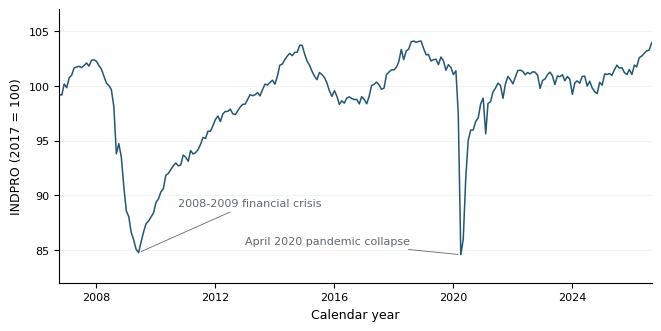

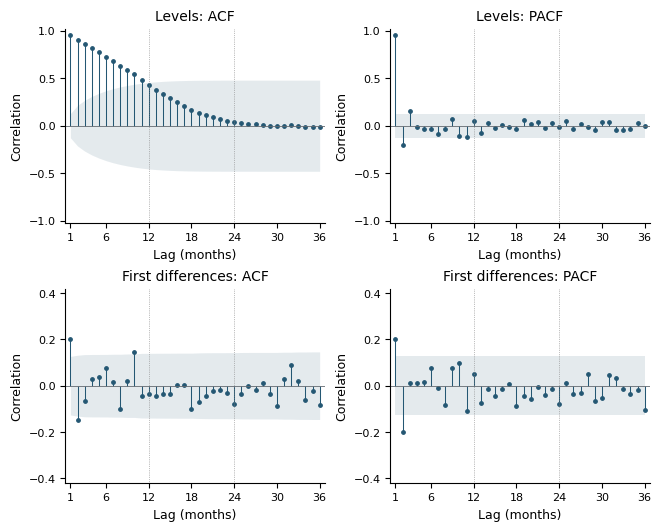

Level ACF(1)=0.957601; difference ACF(1)=0.202419


In [2]:
fig, ax = plt.subplots(figsize=(6.5,3.2),layout='constrained')
ax.plot(y.index,y.values,color=BLUE,lw=1.1)
ax.set(xlabel='Calendar year',ylabel='INDPRO (2017 = 100)',xlim=(y.index[0],y.index[-1]),ylim=(82,107))
ax.xaxis.set_major_locator(mdates.YearLocator(4)); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
for date,label,text_date,text_y in [('2009-06-01','2008-2009 financial crisis','2010-10-01',89),('2020-04-01','April 2020 pandemic collapse','2013-01-01',85.5)]:
    ax.annotate(label,(pd.Timestamp(date),y.loc[date]),xytext=(pd.Timestamp(text_date),text_y),fontsize=8,color=GRAY,arrowprops={'arrowstyle':'-','color':GRAY,'lw':.6})
ax.grid(axis='y',alpha=.15)
save_figure(fig,'figure_1_historical')
fig, axes = plt.subplots(2,2,figsize=(6.5,5.2),layout='constrained')
correlations = {}
for row,(name,series) in enumerate([('Levels',y),('First differences',changes)]):
    a,aci = acf(series,nlags=36,fft=False,adjusted=False,alpha=.05,bartlett_confint=True,missing='raise')
    p,pci = pacf(series,nlags=36,method='ywm',alpha=.05)
    correlations[name] = {'acf':a,'pacf':p}
    for col,(values,intervals,kind) in enumerate([(a,aci,'ACF'),(p,pci,'PACF')]):
        ax=axes[row,col]; lags=np.arange(1,37); bounds=intervals[1:]-values[1:,None]
        ax.fill_between(lags,bounds[:,0],bounds[:,1],color=BLUE,alpha=.12,lw=0)
        ax.vlines(lags,0,values[1:],color=BLUE,lw=.75); ax.scatter(lags,values[1:],s=6,color=BLUE)
        ax.axhline(0,color=GRAY,lw=.6)
        for lag in [12,24]:ax.axvline(lag,color='gray',ls=':',lw=.5)
        ax.set(title=f'{name}: {kind}',xlabel='Lag (months)',ylabel='Correlation',xlim=(.3,36.7),xticks=[1,6,12,18,24,30,36],ylim=(-1.02,1.02) if row==0 else (-.42,.42))
save_figure(fig,'figure_2_acf_pacf')
print(f"Level ACF(1)={correlations['Levels']['acf'][1]:.6f}; difference ACF(1)={correlations['First differences']['acf'][1]:.6f}")

## 2. Candidate models, likelihood and AICc
Fit only the six integrated orders in the report, each with and without drift. This preserves the original comparison, rather than redesigning identification. The two unreported stationary-level sensitivity experiments remain in the original project, not in this report-focused pipeline.

All fits use Gaussian state-space maximum likelihood with the Kalman filter, L-BFGS (`maxiter=2000`, `pgtol=1e-8`, `factr=1e4`), and OIM covariance. AR stationarity/MA invertibility are enforced on the ARMA component; innovation variance is estimated directly. The integrated state has approximate diffuse variance $10^6$, ARMA states stationary initialization, and one initial likelihood contribution is burned. Input N=240, effective likelihood n=239.

In statsmodels `ARIMA`, `trend='t'` is a linear trend in levels, whose coefficient is mean monthly change (drift). With AR terms, the expanded change-equation constant is drift times $(1-\sum\phi_i)$, not generally the drift itself. `trend='n'` fixes drift to zero. MA signs follow $1+\theta_1B+\cdots$.

AICc = AIC + 2k(k+1)/(n-k-1), with k counting AR/MA terms, any drift, and innovation variance. Only identical d=1 likelihood conventions are ranked. All estimation warnings are retained and displayed. No generic model summary is called, since it computes extra diagnostics.

Convergence flags are reported rather than hidden. A candidate that fails its optimizer check is not certified for selection, even when its objective is numerically close. The report-selected model must converge. The clean PyPI/Apple Accelerate build can return a line-search warning for the unselected no-drift ARIMA(0,1,1); this is documented in the audit, without changing optimizer settings. Original OpenBLAS fits all converged.

In [3]:
orders = [(0,1,0),(1,1,0),(2,1,0),(0,1,1),(0,1,2),(1,1,1)]
fits, fit_rows, warning_rows = {}, [], []
optimizer = {'method':'lbfgs','maxiter':2000,'pgtol':1e-8,'factr':1e4,'disp':0}
for order in orders:
    for trend,term in [('n','No drift'),('t','Drift')]:
        label=f'ARIMA{order}'.replace(' ','')
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model=ARIMA(y,order=order,seasonal_order=(0,0,0,0),trend=trend,trend_offset=1,enforce_stationarity=True,enforce_invertibility=True,concentrate_scale=False,missing='raise')
            result=model.fit(method='statespace',method_kwargs=optimizer.copy(),cov_type='oim')
        warning_rows.extend({'Model':label,'Term':term,'Category':w.category.__name__,'Message':str(w.message)} for w in caught)
        k=len(result.params); n=int(result.nobs_effective)
        assert result.nobs==240 and n==239 and result.loglikelihood_burn==1
        assert k==result.df_model==order[0]+order[2]+1+(trend=='t')
        assert np.array_equal(result.model.endog.ravel(),y.values)
        assert np.isclose(result.llf,result.llf_obs[1:].sum())
        aicc=-2*result.llf+2*k+2*k*(k+1)/(n-k-1)
        assert np.isclose(aicc,result.aicc,atol=1e-8)
        assert np.isfinite(result.bse).all(), (label, term, 'Non-finite standard errors')
        # Preserve and expose optimizer failures; never certify a failed candidate.
        converged = bool(result.mle_retvals['converged'])
        assert np.all(np.abs(result.arroots)>1) and np.all(np.abs(result.maroots)>1)
        fits[(order,trend)]=result
        fit_rows.append({'model':label,'term':term,'k':k,'n_effective':n,'log_likelihood':result.llf,'AIC':result.aic,'AICc':aicc,'converged':converged,'optimizer_warnflag':int(result.mle_retvals['warnflag']),'max_abs_gradient':float(np.max(np.abs(result.mle_retvals['gopt'])))})
comparison=pd.DataFrame(fit_rows).sort_values('AICc').reset_index(drop=True)
comparison['delta_AICc']=comparison.AICc-comparison.AICc.min()
(RESULTS/'estimation_warnings.json').write_text(json.dumps(warning_rows,indent=2)+chr(10))
comparison.to_csv(RESULTS/'model_comparison.csv',index=False)
display(comparison.round(6))
if warning_rows:display(pd.DataFrame(warning_rows))
else:print('No estimation warnings.')
# The selected specification is fixed by the submitted report, not chosen anew by code.
selected=fits[((2,1,0),'n')]
assert selected.mle_retvals['converged'], 'The selected model must converge.'
assert comparison.iloc[0]['model']=='ARIMA(2,1,0)' and comparison.iloc[0]['term']=='No drift'
params=selected.params; phi1,phi2=selected.arparams; sigma2=float(params['sigma2'])
intervals=selected.conf_int()
parameter_table=pd.DataFrame({'parameter':params.index,'estimate':params.values,'standard_error':selected.bse.values,'z':selected.tvalues.values,'p_value':selected.pvalues.values,'lower_95':intervals.iloc[:,0].values,'upper_95':intervals.iloc[:,1].values})
parameter_table.to_csv(RESULTS/'parameters.csv',index=False)
with pd.option_context('display.float_format',lambda x:f'{x:.6g}'):display(parameter_table)

,model,term,k,n_effective,log_likelihood,AIC,AICc,converged,optimizer_warnflag,max_abs_gradient,delta_AICc
0,"ARIMA(2,1,0)",No drift,3,239,-372.691641,751.383282,751.485410,True,0,0.000006,0.000000
1,"ARIMA(0,1,2)",No drift,3,239,-373.504490,753.008981,753.111109,True,0,0.000000,1.625699
2,"ARIMA(2,1,0)",Drift,4,239,-372.661642,753.323283,753.494224,True,0,0.000001,2.008814
3,"ARIMA(0,1,1)",No drift,2,239,-375.134397,754.268794,754.319642,False,2,0.000000,2.834232
4,"ARIMA(1,1,1)",No drift,3,239,-374.196022,754.392044,754.494171,True,0,0.000000,3.008761
5,"ARIMA(0,1,2)",Drift,4,239,-373.477575,754.955151,755.126091,True,0,0.000001,3.640681
6,"ARIMA(0,1,1)",Drift,3,239,-375.112617,756.225233,756.327361,True,0,0.000000,4.841951
7,"ARIMA(1,1,1)",Drift,4,239,-374.172301,756.344602,756.515542,True,0,0.000008,5.030132
8,"ARIMA(1,1,0)",No drift,2,239,-377.532433,759.064866,759.115714,True,0,0.000000,7.630304
9,"ARIMA(1,1,0)",Drift,3,239,-377.509195,761.018389,761.120517,True,0,0.000000,9.635107


,Model,Term,Category,Message
0,"ARIMA(0,1,1)",No drift,ConvergenceWarning,Maximum Likelihood optimization failed to conv...


,parameter,estimate,standard_error,z,p_value,lower_95,upper_95
0,ar.L1,0.242541,0.0634084,3.82506,0.000130741,0.118263,0.366819
1,ar.L2,-0.198845,0.0633988,-3.13642,0.00171025,-0.323104,-0.0745858
2,sigma2,1.32361,0.121081,10.9316,8.14285e-28,1.08629,1.56092


The no-drift ARIMA(2,1,0) has the lowest AICc, while no-drift ARIMA(0,1,2) remains plausible (gap about 1.626). Drift does not earn its additional parameter penalty. The selected equation is $\Delta Y_t=0.242541\Delta Y_{t-1}-0.198845\Delta Y_{t-2}+\varepsilon_t$, with working innovation variance approximately 1.323609. Standard errors and p-values use the original normal/OIM convention. The variance p-value is merely a software Wald reference; a zero-variance boundary null is not interpreted as an ordinary two-sided test.

## 3. Residual diagnostics
Use raw one-step prediction errors after `max(loglikelihood_burn, nobs_diffuse)=1`. October 2006's initial error (about 99.2044) is a diffuse initialization artifact, excluded only from diagnostics. All subsequent 239 errors, November 2006–September 2026, remain, including every COVID shock.

Residual ACF/PACF bands match Phase 3: approximately ±1.96/sqrt(239), pointwise white-noise reference limits; PACF uses `ywm`. These are not the Bartlett bands used for the earlier unmodeled series. Ljung–Box uses `model_df=p+q=2`, so df=lag−2. A non-significant test is not proof of independence or normality. An isolated lag-10 crossing found among 36 lags is not a reason to automatically add AR(10)/MA(10).

The MA(2) alternative is checked as in the original work, without another fit. The report figure and compact table concern only the selected model.

,adjusted_df,lb_stat,lb_pvalue
lag,,,
6,4,1.058651,0.900776
10,8,9.106966,0.333353
12,10,11.383613,0.328422
18,16,15.752464,0.470367
24,22,19.145162,0.636348


,lb_stat,MA2_alternative_pvalue
6,2.971923,0.562535
10,10.842951,0.210758
12,12.614070,0.246057
18,16.715705,0.404220
24,19.651050,0.604857


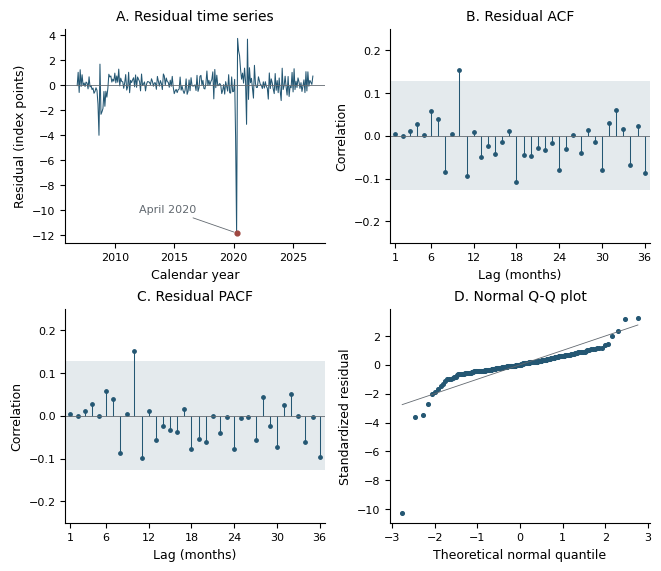

April 2020 residual: -11.816508; residual ACF(10): 0.152756


In [4]:
burn=max(int(selected.loglikelihood_burn),int(selected.nobs_diffuse))
residuals=selected.resid.iloc[burn:].copy()
assert burn==1 and len(residuals)==239 and len(residuals.loc['2020'])==12
assert np.allclose(residuals,selected.filter_results.forecasts_error[0,burn:])
residual_acf=acf(residuals,nlags=36,fft=False,adjusted=False,missing='raise')
residual_pacf=pacf(residuals,nlags=36,method='ywm')
band=stats.norm.ppf(.975)/np.sqrt(len(residuals))
lags=[6,10,12,18,24]
ljung=acorr_ljungbox(residuals,lags=lags,model_df=2,return_df=True,boxpierce=False,auto_lag=False)
ljung.insert(0,'adjusted_df',np.array(lags)-2); ljung.index.name='lag'
for lag,row in ljung.iterrows():
    q=239*241*np.sum(residual_acf[1:lag+1]**2/(239-np.arange(1,lag+1)))
    assert np.isclose(q,row.lb_stat,atol=1e-10)
    assert np.isclose(stats.chi2.sf(q,lag-2),row.lb_pvalue,atol=1e-12)
ljung.to_csv(RESULTS/'ljung_box.csv'); display(ljung.round(6))
alternative_residuals=fits[((0,1,2),'n')].resid.iloc[1:]
alternative_ljung=acorr_ljungbox(alternative_residuals,lags=lags,model_df=2,return_df=True,boxpierce=False,auto_lag=False)
display(alternative_ljung.rename(columns={'lb_pvalue':'MA2_alternative_pvalue'}).round(6))
fig,axes=plt.subplots(2,2,figsize=(6.5,5.6),layout='constrained')
ax=axes[0,0];ax.plot(residuals.index,residuals.values,color=BLUE,lw=.75);ax.axhline(0,color=GRAY,lw=.6)
ax.set(title='A. Residual time series',xlabel='Calendar year',ylabel='Residual (index points)')
ax.xaxis.set_major_locator(mdates.YearLocator(5));ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
april=pd.Timestamp('2020-04-01');ax.scatter([april],[residuals.loc[april]],s=12,color='#9f4740',zorder=3)
ax.annotate('April 2020',(april,residuals.loc[april]),xytext=(-70,15),textcoords='offset points',fontsize=8,color=GRAY,arrowprops={'arrowstyle':'-','color':GRAY,'lw':.6})
for ax,values,title in [(axes[0,1],residual_acf,'B. Residual ACF'),(axes[1,0],residual_pacf,'C. Residual PACF')]:
    k=np.arange(1,37);ax.axhspan(-band,band,color=BLUE,alpha=.12,lw=0);ax.vlines(k,0,values[1:],color=BLUE,lw=.75);ax.scatter(k,values[1:],s=6,color=BLUE);ax.axhline(0,color=GRAY,lw=.6)
    ax.set(title=title,xlabel='Lag (months)',ylabel='Correlation',xlim=(.3,36.7),ylim=(-.25,.25),xticks=[1,6,12,18,24,30,36])
ax=axes[1,1];standardized=(residuals-residuals.mean())/residuals.std(ddof=1)
theory,ordered=stats.probplot(standardized,dist='norm',fit=False)
ax.scatter(theory,ordered,s=7,color=BLUE);ax.plot([min(theory),max(theory)],[min(theory),max(theory)],color=GRAY,lw=.6)
ax.set(title='D. Normal Q-Q plot',xlabel='Theoretical normal quantile',ylabel='Standardized residual')
save_figure(fig,'figure_3_residual_diagnostics')
print(f'April 2020 residual: {residuals.loc[april]:.6f}; residual ACF(10): {residual_acf[10]:.6f}')

The selected model has no significant Ljung–Box result at the reported lags, but retains an isolated lag-10 residual ACF/PACF feature. Heavy tails and uneven variability, especially April 2020's error near −11.82, remain limitations. The alternative also does not reject overall residual autocorrelation at the tested lags. Thus lower AICc supports the report's provisional preference, not a claim that Gaussian innovations or constant volatility have been established.

## 4. Fifty-month Gaussian forecasts
Forecast October 2026–November 2030 with the selected model only. `get_forecast` returns conditional means and future-observation prediction variance; its `conf_int` limits are prediction intervals here, not coefficient confidence intervals. They condition on fitted parameters and do not include parameter-estimation uncertainty. Limits are marginal by horizon, not a simultaneous 50-month band.

For independent validation, propagate monthly changes recursively from the last two observed changes. Let psi[0]=1 and psi[j]=phi1*psi[j−1]+phi2*psi[j−2]; cumulative psi values are the integrated level response to an innovation. Variance at horizon h is sigma2 times the sum of squared level responses from 0 through h−1.

,forecast_month,h,point_forecast,lower_95,upper_95,interval_width
0,2026-10,1,104.1035,101.8486,106.3584,4.5098
11,2027-09,12,103.9682,95.6765,112.2598,16.5833
23,2028-09,24,103.9682,92.3290,115.6073,23.2783
49,2030-11,50,103.9682,87.2342,120.7022,33.4679


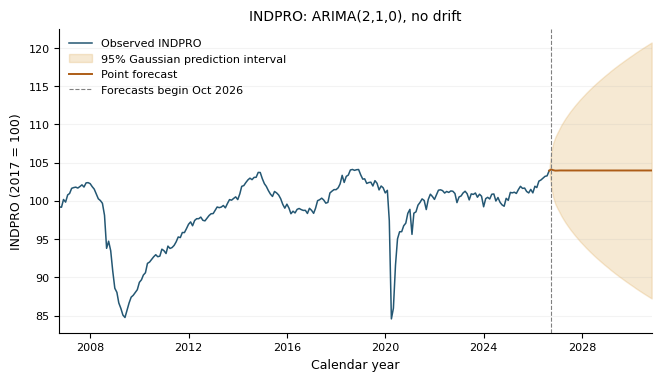

In [5]:
H=50
forecast_dates=pd.date_range('2026-10-01',periods=H,freq='MS')
prediction=selected.get_forecast(steps=H)
point=prediction.predicted_mean; variance=np.asarray(prediction.var_pred_mean); limits=prediction.conf_int(alpha=.05)
assert point.index.equals(forecast_dates) and forecast_dates[-1]==pd.Timestamp('2030-11-01')
last_changes=np.diff(y.values)[-2:]

def simulate_paths(innovations):
    # Same fixed-parameter AR(2)-on-changes recursion as the original Phase 4.
    innovations=np.asarray(innovations,dtype=float)
    assert innovations.ndim==2 and innovations.shape[1]==H
    previous=np.full(len(innovations),last_changes[-1]); older=np.full(len(innovations),last_changes[-2])
    level=np.full(len(innovations),y.iloc[-1]); paths=np.empty_like(innovations)
    for horizon in range(H):
        change=phi1*previous+phi2*older+innovations[:,horizon]
        level=level+change;paths[:,horizon]=level;older,previous=previous,change
    return paths

zero_noise=simulate_paths(np.zeros((1,H)))[0]
assert np.allclose(zero_noise,point.values,atol=1e-8,rtol=0)
psi=np.zeros(H);psi[0]=1
for j in range(1,H):psi[j]=phi1*psi[j-1]+(phi2*psi[j-2] if j>=2 else 0)
level_response=np.cumsum(psi)
assert np.allclose(sigma2*np.cumsum(level_response**2),variance,atol=1e-8,rtol=0)
z=stats.norm.ppf(.975)
assert np.allclose(limits.iloc[:,0],point-z*np.sqrt(variance))
assert np.allclose(limits.iloc[:,1],point+z*np.sqrt(variance))
forecasts=pd.DataFrame({'forecast_month':forecast_dates.strftime('%Y-%m'),'h':np.arange(1,H+1),'point_forecast':point.values,'lower_95':limits.iloc[:,0].values,'upper_95':limits.iloc[:,1].values})
forecasts['interval_width']=forecasts.upper_95-forecasts.lower_95
assert np.isfinite(forecasts.iloc[:,1:].values).all() and (forecasts.lower_95<forecasts.point_forecast).all() and (forecasts.point_forecast<forecasts.upper_95).all()
assert np.all(np.diff(forecasts.interval_width)>=-1e-10)
forecasts.to_csv(RESULTS/'forecasts.csv',index=False)
display(forecasts.loc[forecasts.h.isin([1,12,24,50])].round(4))
fig,ax=plt.subplots(figsize=(6.5,3.7),layout='constrained')
plot_dates=pd.DatetimeIndex([y.index[-1]]).append(forecast_dates)
ax.plot(y.index,y.values,color=BLUE,lw=1.1,label='Observed INDPRO')
ax.fill_between(plot_dates,np.r_[y.iloc[-1],forecasts.lower_95],np.r_[y.iloc[-1],forecasts.upper_95],color='#d99b39',alpha=.22,label='95% Gaussian prediction interval')
ax.plot(plot_dates,np.r_[y.iloc[-1],point.values],color='#ad5d17',lw=1.4,label='Point forecast')
ax.axvline(forecast_dates[0],color='gray',ls='--',lw=.8,label='Forecasts begin Oct 2026')
ax.set(title='INDPRO: ARIMA(2,1,0), no drift',xlabel='Calendar year',ylabel='INDPRO (2017 = 100)',xlim=(y.index[0],forecast_dates[-1]))
ax.xaxis.set_major_locator(mdates.YearLocator(4));ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.legend(fontsize=8,loc='upper left',frameon=False);ax.grid(axis='y',alpha=.15)
save_figure(fig,'figure_4_forecast')

The AR process for changes is stable with zero mean. Predicted changes decay toward zero, so the integrated level approaches a data-dependent constant near 103.968, not zero. Future innovations have lasting level effects, so forecast uncertainty keeps accumulating. This flattening is a model consequence, not an economic prediction of constant production. Fifty months is long relative to a model using two monthly lags; regime changes and future economic information are outside the specification.

## 5. Residual-bootstrap sensitivity
Use **20,000 independent future paths and seed 20261102**. Subtract the mean from the 239 post-initialization residuals, then sample innovations independently with replacement. All economic shocks remain in the empirical pool. Centering is a simulation convention, not an alteration of observations or a refit. Paths start at the final observed level and last two actual changes. Parameters remain fixed.

Zero-noise and unit-impulse checks validate the recursion. An independent Gaussian simulation checks moments against analytic forecasts; this is numerical validation, not real-world coverage testing. Empirical quantiles use NumPy's linear method. The main forecast CSV remains Gaussian. IID residual resampling does not address volatility clustering, future regimes, parameter uncertainty, or out-of-sample performance.

In [6]:
POOL = residuals.to_numpy() - residuals.mean()
N_PATHS, SEED = 20000, 20261102
assert len(POOL)==239 and abs(POOL.mean())<1e-12
impulse=np.zeros((1,H));impulse[0,0]=1
assert np.allclose(simulate_paths(impulse)[0]-zero_noise,level_response,atol=1e-10,rtol=0)
rng=np.random.default_rng(SEED)
bootstrap_paths=simulate_paths(rng.choice(POOL,size=(N_PATHS,H),replace=True))
bootstrap_lower,bootstrap_upper=np.quantile(bootstrap_paths,[.025,.975],axis=0,method='linear')
check_rng=np.random.default_rng(SEED+1)
gaussian_paths=simulate_paths(check_rng.normal(0,np.sqrt(sigma2),size=(N_PATHS,H)))
assert np.max(np.abs(gaussian_paths.var(axis=0)/variance-1))<.05
assert np.max(np.abs(gaussian_paths.mean(axis=0)-point.values)/np.sqrt(variance/N_PATHS))<5
bootstrap=pd.DataFrame({'h':np.arange(1,H+1),'forecast_month':forecast_dates.strftime('%Y-%m'),'gaussian_lower':forecasts.lower_95,'gaussian_upper':forecasts.upper_95,'gaussian_width':forecasts.interval_width,'bootstrap_lower':bootstrap_lower,'bootstrap_upper':bootstrap_upper,'bootstrap_width':bootstrap_upper-bootstrap_lower})
bootstrap['width_ratio']=bootstrap.bootstrap_width/bootstrap.gaussian_width
bootstrap_selected=bootstrap.loc[bootstrap.h.isin([1,12,24,50])]
bootstrap_selected.to_csv(RESULTS/'bootstrap_comparison.csv',index=False)
display(bootstrap_selected.round(4))

,h,forecast_month,gaussian_lower,gaussian_upper,gaussian_width,bootstrap_lower,bootstrap_upper,bootstrap_width,width_ratio
0,1,2026-10,101.8486,106.3584,4.5098,101.9373,105.4680,3.5307,0.7829
11,12,2027-09,95.6765,112.2598,16.5833,91.9448,110.6187,18.6739,1.1261
23,24,2028-09,92.3290,115.6073,23.2783,89.3334,113.5050,24.1715,1.0384
49,50,2030-11,87.2342,120.7022,33.4679,85.0809,118.2542,33.1733,0.9912


The empirical intervals are asymmetric and their width differences vary by horizon: about 21.7% narrower at h=1, 12.6% wider at h=12, and less than 1% different at h=50. This is distributional sensitivity, not proof of better prediction or calibrated 95% coverage. Heavy tails and time-varying variability remain concerns for both procedures.

## 6. Reference checks and reproducibility record
The reference JSON comes from the original executed analysis, forecast export and submitted report; it never feeds the estimates. Fail visibly if values differ beyond the documented tolerances. Checks cover data identity, reported coefficients and AICc, forecast dates and selected intervals, bootstrap quantiles, adjusted Ljung–Box p-values, initialization, and unchanged COVID observations. No new statistical tests are added solely to populate infrastructure.

In [7]:
tol=reference['tolerances']
checks={}
checks['frozen_data_hash']=hashlib.sha256(raw_path.read_bytes()).hexdigest()==reference['source_sha256']
checks['sample_and_covid_unchanged']=y.equals(unchanged_sample) and np.array_equal(y.loc['2020'].values,original.loc['2020'].values)
checks['selected_parameters']=all(abs(float(params[name])-value)<=tol['parameters_absolute'] for name,value in reference['parameters'].items())
checks['selected_convergence']=bool(selected.mle_retvals['converged'])
checks['all_candidate_aicc']=all(abs(float(comparison.loc[comparison.model.eq(ref['model']) & comparison.term.eq(ref['term']),'AICc'].iloc[0])-ref['AICc'])<=tol['aicc_absolute'] for ref in reference['candidate_aicc'])
checks['selected_aicc']=abs(selected.aicc-reference['aicc'])<=tol['aicc_absolute']
checks['forecast_dates']=forecasts.forecast_month.tolist()==pd.date_range('2026-10-01',periods=50,freq='MS').strftime('%Y-%m').tolist()
checks['forecast_reference']=all(abs(float(forecasts.loc[forecasts.h.eq(ref['h']),key].iloc[0])-ref[key])<=tol['forecast_absolute'] for ref in reference['forecast_rows'] for key in ['point_forecast','lower_95','upper_95','interval_width'])
checks['bootstrap_reference']=all(abs(float(bootstrap.loc[bootstrap.h.eq(ref['h']),key].iloc[0])-ref[refkey])<=tol['bootstrap_absolute'] for ref in reference['bootstrap_rows'] for key,refkey in [('bootstrap_lower','Bootstrap lower'),('bootstrap_upper','Bootstrap upper'),('bootstrap_width','Bootstrap width')])
checks['ljung_box_reference']=all(abs(float(ljung.loc[int(lag),'lb_pvalue'])-value)<=tol['ljung_box_absolute'] for lag,value in reference['ljung_box_pvalues'].items())
checks['initialization']=burn==1 and len(residuals)==239
checks['analytic_forecasts']=np.allclose(zero_noise,point.values,atol=1e-8,rtol=0)
checks['analytic_variance']=np.allclose(sigma2*np.cumsum(level_response**2),variance,atol=1e-8,rtol=0)
checks['bootstrap_setup']=N_PATHS==reference['bootstrap_paths'] and SEED==reference['bootstrap_seed']
assert all(checks.values()),checks
metrics={'sample_start':str(y.index[0].date()),'sample_end':str(y.index[-1].date()),'n':len(y),'residual_n':len(residuals),'selected_model':'ARIMA(2,1,0), no drift','parameters':{k:float(v) for k,v in params.items()},'AICc':float(selected.aicc),'forecast_horizon':H,'bootstrap_paths':N_PATHS,'bootstrap_seed':SEED,'versions':versions,'warning_count':len(warning_rows),'nonconverged_candidates':comparison.loc[~comparison.converged,['model','term','optimizer_warnflag','max_abs_gradient']].to_dict(orient='records')}
(RESULTS/'metrics.json').write_text(json.dumps(metrics,indent=2)+'\n')
(RESULTS/'validation.json').write_text(json.dumps({'passed':all(checks.values()),'checks':{k:bool(v) for k,v in checks.items()}},indent=2)+'\n')
display(pd.Series(checks,name='Passed').to_frame())
print('All reference checks passed. No out-of-sample accuracy or coverage claims are made.')

,Passed
frozen_data_hash,True
sample_and_covid_unchanged,True
selected_parameters,True
selected_convergence,True
all_candidate_aicc,True
selected_aicc,True
forecast_dates,True
forecast_reference,True
bootstrap_reference,True
ljung_box_reference,True


All reference checks passed. No out-of-sample accuracy or coverage claims are made.
